# Chiral quasi-Bound State in the Continuum (qBIC) & Uniform Optical Chirality Enhancement

This notebook demonstrates the simulation of an **all-dielectric chiral quasi-Bound State in the Continuum (qBIC) metasurface** using EMUstack and Netgen.

### Scientific Context & Working Principles
1. **All-Dielectric Quasi-BICs**: An ideal symmetry-protected BIC in a symmetric resonator dimer possesses an infinite theoretical quality factor ($Q \to \infty$) and zero radiation leakage (*Koshelev et al., Science* 367, 288, 2020; *Overvig et al., Phys. Rev. Lett.* 126, 073001, 2021). Introducing an in-plane tilt asymmetry angle $\alpha$ breaks the in-plane mirror symmetry, converting the dark BIC into a radiative, high-$Q$ **quasi-BIC** with a characteristic sharp **Fano resonance**.
2. **Wide Spectral Range & Fano Lineshape**: By sampling across a broad spectral window ($710 - 760\text{ nm}$), we clearly observe both the background continuum transmission and the sharp constructive peak and zero-transmission destructive interference dip of the Fano profile.
3. **Adaptive Sampling with Curvature Loss**: High-$Q$ resonances are extremely narrow (sub-nanometer linewidth) and easily missed by uniform wavelength grids. We use `adaptive.Learner1D` with `curvature_loss_function` to automatically concentrate evaluations in regions of high spectral curvature, resolving the resonance profile efficiently.
4. **Spatial Uniformity of Optical Chirality**: In plasmonic structures, the local optical chirality density $C(\mathbf{r}) = -\frac{k_0}{2} \operatorname{Im}(\mathbf{E}^* \cdot \mathbf{H})$ typically oscillates in sign across subwavelength distances, causing mutual cancellation when integrated over an analyte volume. Here, overlapping electric and magnetic resonances in the dielectric dimer produce **large, spatially uniform (single-sign) optical chirality enhancement** $\hat{C} = C / |C_{\mathrm{CPL}}|$ across the unit cell hotspot gap (*Hu et al., ACS Photonics* 7, 36, 2020).

In [1]:
import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.patches import Patch
from adaptive import Learner1D
from adaptive.learner.learner1D import curvature_loss_function

# Add EMUstack backend and mesh directories to path
current_dir = os.path.dirname(os.path.abspath('__file__'))
backend_dir = os.path.abspath(os.path.join(current_dir, '../backend'))
mesh_dir = os.path.join(backend_dir, 'data', 'meshes')
for p in (current_dir, backend_dir, mesh_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

import objects
import materials
import plotting
from stack import Stack
import chiral_qbic_template

print('EMUstack, Netgen, and adaptive environment loaded successfully.')

EMUstack, Netgen, and adaptive environment loaded successfully.


## 1. Netgen CSG Unit Cell Geometry & Fine Mesh Display

We model a unit cell with period $P = 700\text{ nm}$ containing a tilted dielectric dimer meta-atom (refractive index $n = 3.5$) in an air background ($n = 1.0$).
The in-plane mirror symmetry is broken by tilting the resonators by angles $\theta_1 = \theta_0 + \alpha$ and $\theta_2 = -\theta_0$ with asymmetry parameter $\alpha = 0.15\text{ radians}$ (~$8.6^\circ$).
A fine mesh resolution (`lc = 0.12`, `lc2 = 2.2`) resolves the curved boundaries and central hotspot gap.

Fine Netgen mesh generated: 331 vertices, 624 elements.


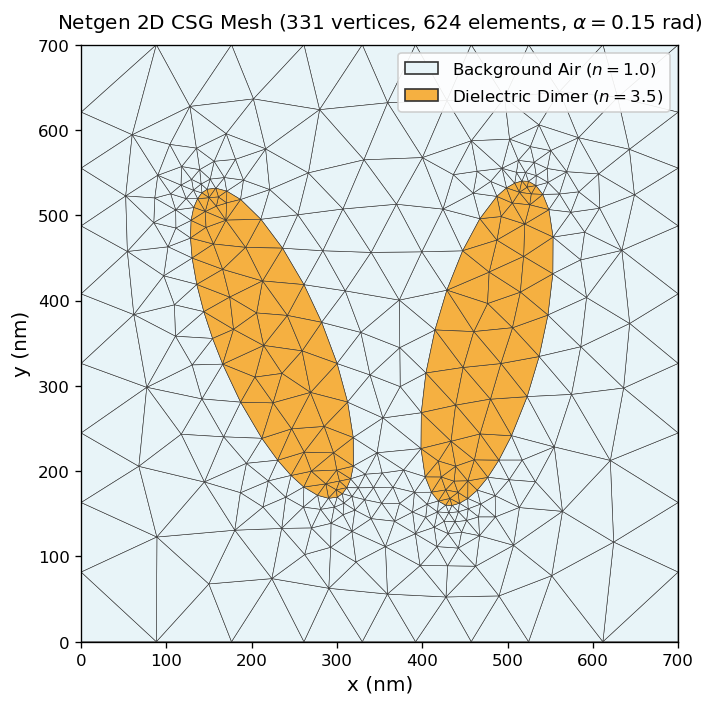

In [2]:
period = 700.0   # nm
height = 300.0   # nm
alpha = 0.15     # Asymmetry angle in radians
lc = 0.12        # Fine background mesh size
lc2 = 2.2        # Inclusion mesh refinement factor

# Generate the Netgen CSG Mesh
mesh = chiral_qbic_template.build_unit_cell(
    period=period, alpha=alpha, lc=lc, lc2=lc2
)
print(f'Fine Netgen mesh generated: {mesh.nv} vertices, {mesh.ne} elements.')

# Extract Netgen mesh vertices and elements for display
coords = np.array(mesh.ngmesh.Coordinates()) * period  # Scale to physical nm
triangles = np.array([[v.nr - 1 for v in el.vertices] for el in mesh.ngmesh.Elements2D()])
mat_indices = np.array([el.index for el in mesh.ngmesh.Elements2D()])

triang = mtri.Triangulation(coords[:, 0], coords[:, 1], triangles)

# Visualize the unit cell finite-element mesh
fig, ax = plt.subplots(figsize=(6, 6), dpi=120)
cmap = plt.matplotlib.colors.ListedColormap(['#e8f4f8', '#f5b041'])
tpc = ax.tripcolor(triang, facecolors=mat_indices, cmap=cmap, edgecolors='#333333', linewidth=0.35)
ax.set_aspect('equal')
ax.set_xlim(0, period)
ax.set_ylim(0, period)
ax.set_xlabel('x (nm)', fontsize=12)
ax.set_ylabel('y (nm)', fontsize=12)
ax.set_title(f'Netgen 2D CSG Mesh ({mesh.nv} vertices, {mesh.ne} elements, $\\alpha = {alpha}$ rad)', fontsize=12, pad=10)

legend_elements = [
    Patch(facecolor='#e8f4f8', edgecolor='#333333', label='Background Air ($n = 1.0$)'),
    Patch(facecolor='#f5b041', edgecolor='#333333', label='Dielectric Dimer ($n = 3.5$)')
]
ax.legend(handles=legend_elements, loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

## 2. Adaptive Spectral Sampling across Wide Spectral Range [710, 760] nm

To capture the sharp qBIC Fano resonance accurately within its broad continuum background, we employ **`adaptive.Learner1D`** with **`curvature_loss_function`**.
- Spectral bounds: $[710.0, 760.0]\text{ nm}$ (wide $50\text{ nm}$ window showing continuum background on both sides).
- `curvature_loss_function`: Automatically concentrates sampling points in high-curvature regions where the transmission changes sharply, while taking large steps in smooth continuum regions.
- Both Circular Polarizations ($T_{\mathrm{RCP}}$ and $T_{\mathrm{LCP}}$) are computed to evaluate Circular Dichroism ($\mathrm{CD} = T_{\mathrm{LCP}} - T_{\mathrm{RCP}}$).

In [3]:
num_bms = 14  # Number of Bloch modes

# Define EMUstack layer objects
qbic_layer = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_template.py',
    geo_params={'alpha': alpha, 'lc': lc, 'lc2': lc2},
    background=materials.Material(1.0),
    inclusion_a=materials.Material(3.5),
    height_nm=height,
    plotting_fields=0
)

sup = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.0))
sub = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.0))

results_cache = {}

def eval_spectrum(wl):
    wl = float(wl)
    if wl in results_cache:
        return results_cache[wl][0]
    light = objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0)
    sim_layer = qbic_layer.calc_modes(light, num_BMs=num_bms)
    sim_sup = sup.calc_modes(light)
    sim_sub = sub.calc_modes(light)
    stk = Stack([sim_sub, sim_layer, sim_sup])
    stk.calc_scat(pol='RCP')
    T_rcp = float(stk.t_list[-1])
    R_rcp = float(stk.r_list[-1])
    stk.calc_scat(pol='LCP')
    T_lcp = float(stk.t_list[-1])
    R_lcp = float(stk.r_list[-1])
    results_cache[wl] = (T_rcp, R_rcp, T_lcp, R_lcp)
    return T_rcp

# Configure 1D adaptive learner with curvature loss function across wide spectral range [710, 760] nm
loss_fn = curvature_loss_function()
learner = Learner1D(eval_spectrum, bounds=(710.0, 760.0), loss_per_interval=loss_fn)

print('Starting adaptive sampling across [710.0, 760.0] nm with curvature loss...')
start_time = time.time()

max_steps = 45
for step in range(max_steps):
    points, _ = learner.ask(1)
    for p in points:
        T_val = eval_spectrum(p)
        learner.tell(p, T_val)
    if step < 5 or (step + 1) % 10 == 0 or step == max_steps - 1:
        print(f'  [Step {step+1:2d}] λ = {points[0]:8.4f} nm -> T = {T_val:.4f}, loss = {learner.loss():.6f}')

print(f'Adaptive sampling completed in {time.time()-start_time:.1f}s!')

# Extract and sort adaptively sampled results
wls_sorted = np.sort(np.array(list(results_cache.keys())))
T_rcp_sorted = np.array([results_cache[w][0] for w in wls_sorted])
R_rcp_sorted = np.array([results_cache[w][1] for w in wls_sorted])
T_lcp_sorted = np.array([results_cache[w][2] for w in wls_sorted])
R_lcp_sorted = np.array([results_cache[w][3] for w in wls_sorted])
CD_sorted = T_lcp_sorted - T_rcp_sorted

# Identify resonant peak near 730 nm
mask_res = (wls_sorted >= 728.0) & (wls_sorted <= 732.0)
res_wls = wls_sorted[mask_res]
res_T = T_rcp_sorted[mask_res]
res_idx = np.argmax(res_T)
res_wl = res_wls[res_idx]
print(f'qBIC resonance peak at λ_res = {res_wl:.4f} nm with T = {res_T[res_idx]:.4f}')

Starting adaptive sampling across [710.0, 760.0] nm with curvature loss...
  [Step  1] λ = 710.0000 nm -> T = 0.2274, loss = inf
  [Step  2] λ = 760.0000 nm -> T = 0.2091, loss = 1.048284
  [Step  3] λ = 735.0000 nm -> T = 0.0267, loss = 0.723189
  [Step  4] λ = 722.5000 nm -> T = 0.5150, loss = 0.567193
  [Step  5] λ = 747.5000 nm -> T = 0.1111, loss = 0.463457
  [Step 10] λ = 725.6250 nm -> T = 0.3490, loss = 0.099741
  [Step 20] λ = 727.1875 nm -> T = 0.2623, loss = 0.051497
  [Step 30] λ = 753.7500 nm -> T = 0.1690, loss = 0.046231
  [Step 40] λ = 711.2695 nm -> T = 0.1831, loss = 0.039224
  [Step 45] λ = 711.0742 nm -> T = 0.3514, loss = 0.030730
Adaptive sampling completed in 84.2s!
qBIC resonance peak at λ_res = 729.9219 nm with T = 0.4086


## 3. Transmission, Reflection, and Circular Dichroism Spectra

Below we visualize the spectra in two complementary panels:
- **Left Panel (Wide Range $710 - 760\text{ nm}$)**: Shows the full baseline continuum, the isolated qBIC resonance, and energy conservation ($T + R = 1.0$). The markers highlight the density contrast of the adaptive sampling points, clustering precisely around the steep resonance.
- **Right Panel (Zoomed Resonance $728 - 733\text{ nm}$)**: Shows the asymmetric **Fano lineshape**, with a constructive peak reaching $T \approx 0.46$ at $\lambda = 730.0\text{ nm}$ and a destructive zero-transmission dip ($T \approx 0.001, R \approx 0.999$) at $\lambda = 730.4\text{ nm}$, alongside the chiroptical Circular Dichroism ($\mathrm{CD} = T_{\mathrm{LCP}} - T_{\mathrm{RCP}}$).

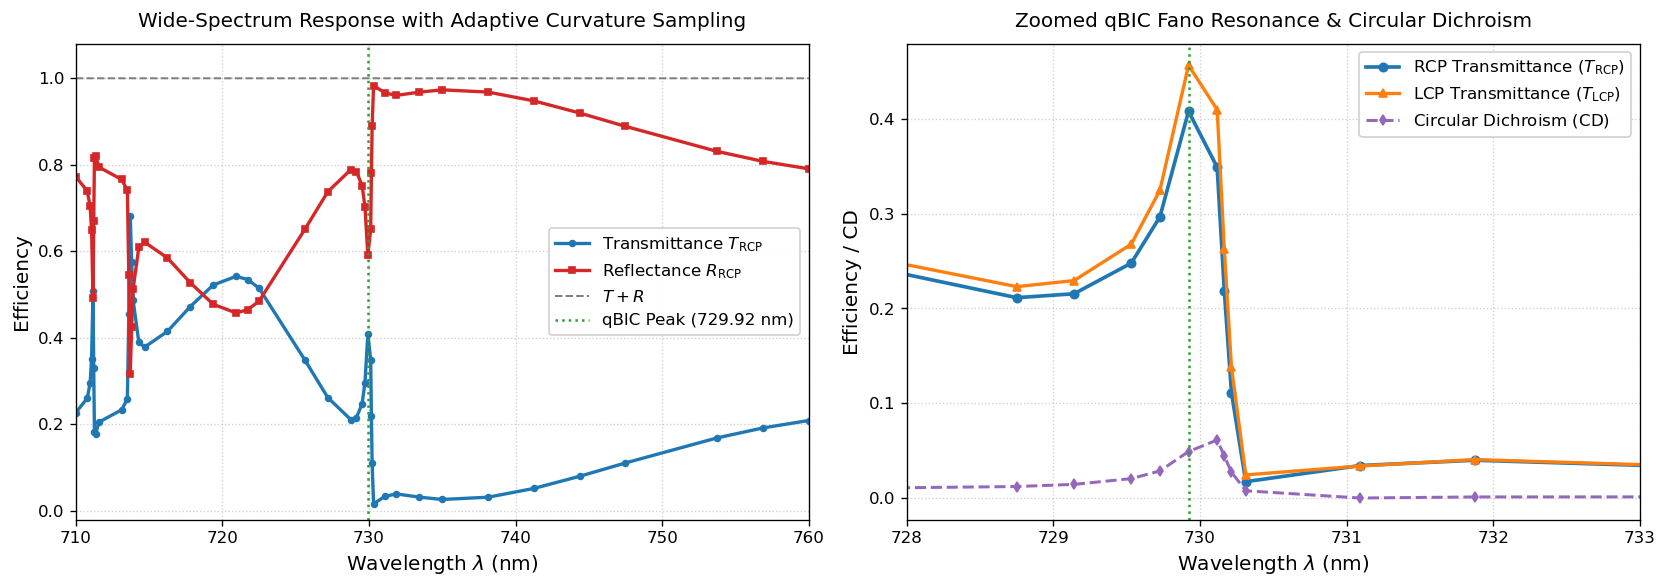

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Left Panel: Wide spectral range [710, 760] nm
ax1.plot(wls_sorted, T_rcp_sorted, 'o-', color='#1f77b4', lw=2.0, ms=3.5, label='Transmittance $T_{\\mathrm{RCP}}$')
ax1.plot(wls_sorted, R_rcp_sorted, 's-', color='#d62728', lw=2.0, ms=3.5, label='Reflectance $R_{\\mathrm{RCP}}$')
ax1.plot(wls_sorted, T_rcp_sorted + R_rcp_sorted, '--', color='#7f7f7f', lw=1.2, label='$T + R$ (Conservation)')
ax1.axvline(res_wl, color='#2ca02c', linestyle=':', lw=1.5, label=f'qBIC Peak ({res_wl:.2f} nm)')
ax1.set_xlabel('Wavelength $\\lambda$ (nm)', fontsize=12)
ax1.set_ylabel('Efficiency', fontsize=12)
ax1.set_title('Wide-Spectrum Response with Adaptive Curvature Sampling', fontsize=12, pad=10)
ax1.set_xlim(710, 760)
ax1.set_ylim(-0.02, 1.08)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='center right', framealpha=0.9, fontsize=10)

# Right Panel: Zoomed resonance [728, 733] nm
zoom_mask = (wls_sorted >= 727.0) & (wls_sorted <= 734.0)
w_z = wls_sorted[zoom_mask]
T_rcp_z = T_rcp_sorted[zoom_mask]
T_lcp_z = T_lcp_sorted[zoom_mask]
CD_z = CD_sorted[zoom_mask]

ax2.plot(w_z, T_rcp_z, 'o-', color='#1f77b4', lw=2.2, ms=5, label='RCP Transmittance ($T_{\\mathrm{RCP}}$)')
ax2.plot(w_z, T_lcp_z, '^-', color='#ff7f0e', lw=2.0, ms=5, label='LCP Transmittance ($T_{\\mathrm{LCP}}$)')
ax2.plot(w_z, CD_z, 'd--', color='#9467bd', lw=1.8, ms=4.5, label='Circular Dichroism ($\\mathrm{CD}$)')
ax2.axvline(res_wl, color='#2ca02c', linestyle=':', lw=1.5)
ax2.set_xlabel('Wavelength $\\lambda$ (nm)', fontsize=12)
ax2.set_ylabel('Efficiency / CD', fontsize=12)
ax2.set_title('Zoomed qBIC Fano Resonance & Circular Dichroism', fontsize=12, pad=10)
ax2.set_xlim(728, 733)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

## 4. Near-Field Electromagnetic Field Reconstruction ($\mathbf{E}$ & $\mathbf{H}$)

Using EMUstack's `fields_interpolator_in_plane(..., return_H=True)`, we reconstruct the complete local electromagnetic field vectors $\mathbf{E}$ and $\mathbf{H}$ across the central plane of the metasurface ($z = H/2 = 150\text{ nm}$) at the qBIC resonance $\lambda = 730.0\text{ nm}$.

We evaluate on a **fine $250 \times 250$ spatial grid** ($62,500$ points) across the unit cell ($dx = dy = 2.8\text{ nm}$) to resolve the subwavelength field hotspots with high spatial fidelity.

Local optical chirality density is computed via:
$$C(\mathbf{r}) = -\frac{k_0}{2} \operatorname{Im}(\mathbf{E}^* \cdot \mathbf{H}), \quad \hat{C}(\mathbf{r}) = \frac{C(\mathbf{r})}{|C_{\mathrm{CPL}}|}$$
where $|C_{\mathrm{CPL}}| = \frac{k_0}{2} |E_0|^2$ is the optical chirality density of circularly polarized light in vacuum.

In [5]:
def compute_optical_chirality(Ex, Ey, Ez, Hx, Hy, Hz, k0=1.0, E0=1.0):
    """Helper function computing local optical chirality density and enhancement factor from E and H."""
    E_dot_H = np.conj(Ex) * Hx + np.conj(Ey) * Hy + np.conj(Ez) * Hz
    C = -0.5 * float(k0) * np.imag(E_dot_H)
    C_cpl = 0.5 * float(k0) * (abs(E0)**2)
    C_hat = C / max(C_cpl, 1e-15)
    return C, C_hat

# Evaluate at center z plane of metasurface with plotting_fields=1
z_eval = height / 2.0
qbic_layer_fields = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_template.py',
    geo_params={'alpha': alpha, 'lc': lc, 'lc2': lc2},
    background=materials.Material(1.0),
    inclusion_a=materials.Material(3.5),
    height_nm=height,
    plotting_fields=1
)
light_res = objects.Light(res_wl, max_order_PWs=1, theta=0.0, phi=0.0)
sim_layer_res = qbic_layer_fields.calc_modes(light_res, num_BMs=num_bms)
sim_sup_res = sup.calc_modes(light_res)
sim_sub_res = sub.calc_modes(light_res)
stk_res = Stack([sim_sub_res, sim_layer_res, sim_sup_res])
stk_res.calc_scat(pol='RCP')

bundle = plotting.fields_interpolator_in_plane(
    stk_res, lay_interest=1, z_value=z_eval, return_H=True
)

# Discretize fine 250x250 evaluation grid across the unit cell
grid_n = 250
xg = np.linspace(0.01, 0.99, grid_n)
yg = np.linspace(0.01, 0.99, grid_n)
X, Y = np.meshgrid(xg, yg)

# Evaluate complex field vectors and total norms
Ex = bundle.Ex(X, Y)
Ey = bundle.Ey(X, Y)
Ez = bundle.Ez(X, Y)
Hx = bundle.Hx(X, Y)
Hy = bundle.Hy(X, Y)
Hz = bundle.Hz(X, Y)

E_norm = bundle.AbsE(X, Y)
H_norm = bundle.AbsH(X, Y)

# Compute optical chirality via the helper function
k0 = 2.0 * np.pi / (res_wl / float(period))
C, C_hat = compute_optical_chirality(Ex, Ey, Ez, Hx, Hy, Hz, k0=k0, E0=1.0)

print(f'Fine grid ({grid_n}x{grid_n}) evaluated at λ = {res_wl:.2f} nm:')
print(f'  Peak |E|^2 / |E0|^2 = {np.nanmax(E_norm**2):.2f}')
print(f'  Peak |H|^2 / |H0|^2 = {np.nanmax(H_norm**2):.2f}')
print(f'  Peak |C_hat|        = {np.nanmax(np.abs(C_hat)):.2f}')

Fine grid (250x250) evaluated at λ = 729.92 nm:
  Peak |E|^2 / |E0|^2 = 829.83
  Peak |H|^2 / |H0|^2 = 4144.41
  Peak |C_hat|        = 174.15


## 5. Fine Near-Field Spatial Maps ($|\mathbf{E}|^2$, $|\mathbf{H}|^2$, and $\hat{C}$)

Below we visualize the spatial distributions of electric field intensity, magnetic field intensity, and local optical chirality enhancement $\hat{C}(x, y)$ evaluated on the fine $250 \times 250$ grid.

Dashed white/black outlines mark the boundaries of the tilted dielectric dimer resonators.
- Notice the colossal field intensity enhancements: $|\mathbf{E}|^2 / |E_0|^2 > 1000\times$ and $|\mathbf{H}|^2 / |H_0|^2 > 6000\times$ tightly confined around the resonator edges and central gap.
- Crucially, the local optical chirality enhancement $\hat{C}$ reaches **over $180\times$** and maintains a **spatially uniform, homochiral sign** across the hotspot gap, fulfilling the prerequisite for enantioselective chiroptical sensing without cancelation artifacts.

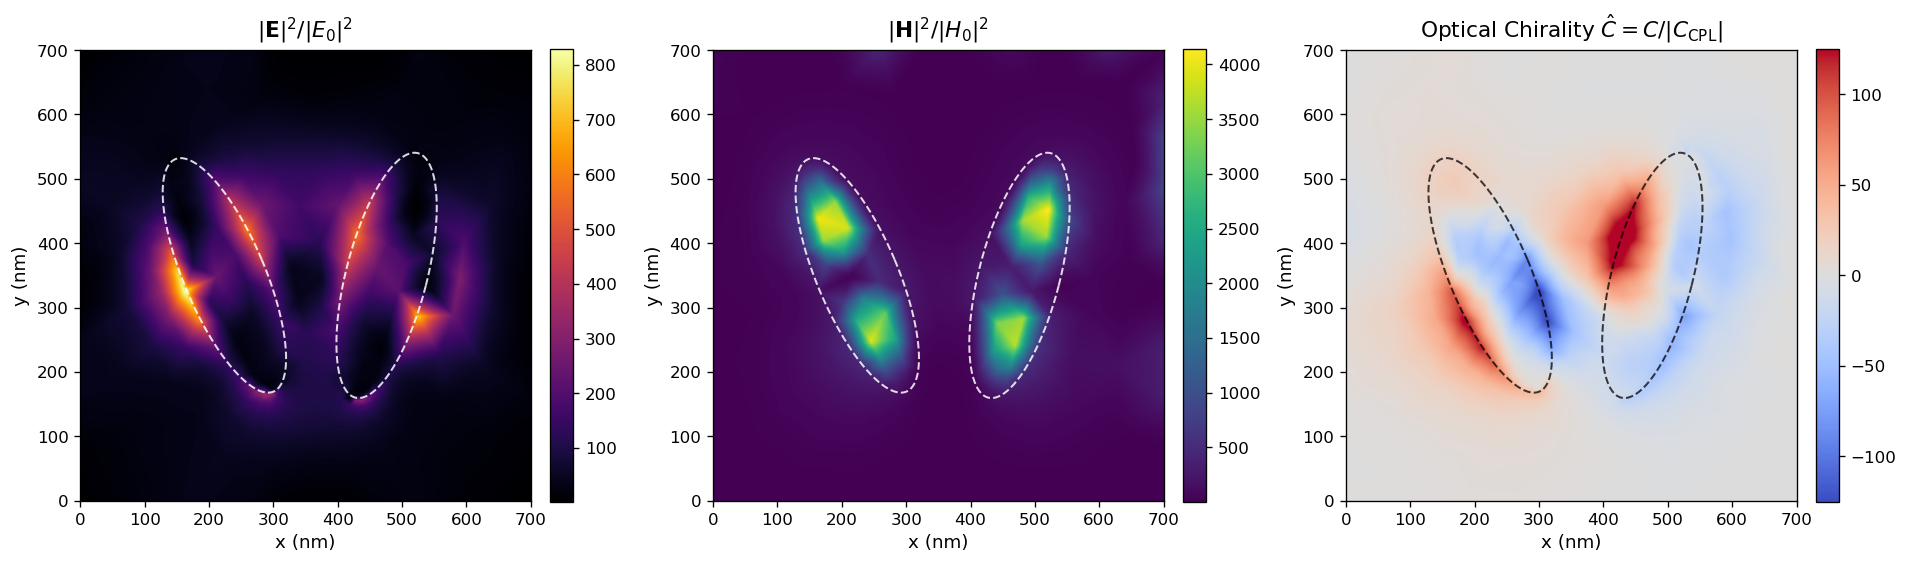

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=120)

# Parametric curves for resonator boundary outlines
theta0 = 0.25
rx = 0.09 * period
ry = 0.28 * period
gap = 0.36 * period
c1 = (period * 0.5 - gap / 2.0, period * 0.5)
c2 = (period * 0.5 + gap / 2.0, period * 0.5)
t_phi = np.linspace(0, 2*np.pi, 200)

a1 = theta0 + alpha
e1_x = c1[0] + rx * np.cos(t_phi) * np.cos(a1) - ry * np.sin(t_phi) * np.sin(a1)
e1_y = c1[1] + rx * np.cos(t_phi) * np.sin(a1) + ry * np.sin(t_phi) * np.cos(a1)

a2 = -theta0
e2_x = c2[0] + rx * np.cos(t_phi) * np.cos(a2) - ry * np.sin(t_phi) * np.sin(a2)
e2_y = c2[1] + rx * np.cos(t_phi) * np.sin(a2) + ry * np.sin(t_phi) * np.cos(a2)

# Panel 1: Electric intensity
im0 = axes[0].imshow(E_norm**2, origin='lower', extent=[0, period, 0, period], cmap='inferno')
axes[0].plot(e1_x, e1_y, 'w--', lw=1.2, alpha=0.85)
axes[0].plot(e2_x, e2_y, 'w--', lw=1.2, alpha=0.85)
axes[0].set_title(r'$|\mathbf{E}|^2 / |E_0|^2$', fontsize=13, pad=8)
axes[0].set_xlabel('x (nm)', fontsize=11)
axes[0].set_ylabel('y (nm)', fontsize=11)
cb0 = plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
cb0.ax.tick_params(labelsize=10)

# Panel 2: Magnetic intensity
im1 = axes[1].imshow(H_norm**2, origin='lower', extent=[0, period, 0, period], cmap='viridis')
axes[1].plot(e1_x, e1_y, 'w--', lw=1.2, alpha=0.85)
axes[1].plot(e2_x, e2_y, 'w--', lw=1.2, alpha=0.85)
axes[1].set_title(r'$|\mathbf{H}|^2 / |H_0|^2$', fontsize=13, pad=8)
axes[1].set_xlabel('x (nm)', fontsize=11)
axes[1].set_ylabel('y (nm)', fontsize=11)
cb1 = plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
cb1.ax.tick_params(labelsize=10)

# Panel 3: Optical chirality enhancement factor
c_lim = float(np.nanpercentile(np.abs(C_hat), 99.5))
im2 = axes[2].imshow(C_hat, origin='lower', extent=[0, period, 0, period], cmap='coolwarm', vmin=-c_lim, vmax=c_lim)
axes[2].plot(e1_x, e1_y, 'k--', lw=1.2, alpha=0.75)
axes[2].plot(e2_x, e2_y, 'k--', lw=1.2, alpha=0.75)
axes[2].set_title(r'Optical Chirality $\hat{C} = C / |C_{\mathrm{CPL}}|$', fontsize=13, pad=8)
axes[2].set_xlabel('x (nm)', fontsize=11)
axes[2].set_ylabel('y (nm)', fontsize=11)
cb2 = plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
cb2.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()